# Case Study 2 — Whole-scalp spectral analysis of resting-state EEG (R)

This is the **R implementation** of Case Study 2. It implements the
analysis described in Section 4.2 of the companion paper. The same
analysis is also available as
[Python code](../../../python/CaseStudy_2/CaseStudy_2.ipynb).

The research question is:

> *Does the spectral profile of resting-state EEG relate to global
> cognitive functioning, without restricting the analysis in advance to
> a specific frequency band or region?*

Where [Case Study 1](../../case1/code/CaseStudy_1.ipynb) reduces the EEG
signal to four theory-driven scalar features, this case study keeps the
**full power spectral density** (PSD, 1–40 Hz, every channel) and asks
broadly *where* — across the whole scalp and spectrum — resting EEG
power relates to global cognition (MoCA), motivated by a well-established
clinical observation: right-hemisphere stroke is frequently accompanied
by pathological EEG slowing (more delta/theta power over the affected
region) that tracks the severity of impairment (Finnigan & Van Putten,
2013).

## A note on the data

- The EEG spectra used here are **real, anonymised recordings**.
- The neuropsychological table (age, sex, CRIq, MoCA) is **synthetic**,
  as in Case Study 1.
- Because the two do not come from the same assessment, the `moca`
  column was deliberately linked to a real, montage-based property of
  each EEG recording — see the notice at the top of
  `data/generate_datasets.ipynb` for the full disclosure. **The
  resulting brain–behaviour association should not be read as a real
  clinical finding**; it exists so this case study has something real to
  recover.

## Pipeline

1. **Data Wrangling** — load & align, inspect, missing data, log-power
   distributions, covariate strategy
2. **Analysis** — descriptive stats, a Case-Study-1-style baseline model,
   mass-univariate partial correlation, cluster-based permutation
   (primary whole-spectrum test + a pre-registered secondary/confirmatory
   test)
3. **Export** — figures and tables (CSV + Excel)
4. **Strengths and limitations**

> The Python version uses `mne` for electrode positions, spatial
> adjacency, and topographic plots. R has no equivalent package, so
> this instead reads three small, plain-CSV files — channel
> positions, channel adjacency, and the scalp outline — pre-exported
> from the real montage by
> [`data/EEG/PSD/compute_montage_assets.ipynb`](../../../data/EEG/PSD/compute_montage_assets.ipynb).
> Everything downstream (the statistics, the cluster test, the topomap
> interpolation) is plain R, defined here.

## 0. Setup

Import the libraries we will use throughout the analysis.

In [1]:
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(patchwork)  # combine ggplot panels into one figure
  library(Matrix)     # sparse adjacency matrices (part of base R)
  library(MASS)        # pseudo-inverse, MASS::ginv (part of base R)
  library(igraph)       # connected components, for cluster-finding
  library(openxlsx)      # Excel export
})

theme_set(theme_minimal())

Define input/output folders

In [2]:
# Input
DATA_DIR <- "../../../data"
NPSY_CSV <- file.path(DATA_DIR, "dataset_NPSY.csv")
ERP_CSV  <- file.path(DATA_DIR, "dataset_ERP.csv")
PSD_DIR  <- file.path(DATA_DIR, "EEG", "PSD")

# Output
OUTPUTS <- "../outputs"
FIGS    <- file.path(OUTPUTS, "figures")
RESULTS <- file.path(OUTPUTS, "results")
dir.create(FIGS, recursive = TRUE, showWarnings = FALSE)
dir.create(RESULTS, recursive = TRUE, showWarnings = FALSE)

---
## 1. Data Wrangling

### 1.1 Load data

The EEG spectra are stored as a `[subjects x channels x frequencies]`
array, linked to the neuropsychological table by `subject_id`. Unlike
Case Study 1's CSV files, this is too large for a spreadsheet — it comes
as three companion files (the array, the channel names, the frequency
axis), saved by Python's `numpy.save`. R has no package in common use
for `.npy` files, so we read the (simple, documented) binary format
directly — about twenty lines, defined once below.

In [3]:
read_npy <- function(path) {
  # Minimal reader for the subset of the .npy format we actually need:
  # version 1.0/2.0 header, C-order (row-major), float32/float64 data.
  con <- file(path, "rb")
  on.exit(close(con))
  magic <- readBin(con, "raw", n = 6)
  stopifnot(rawToChar(magic[2:6]) == "NUMPY")
  major <- readBin(con, "integer", n = 1, size = 1, signed = FALSE)
  readBin(con, "integer", n = 1, size = 1, signed = FALSE)  # minor version, unused
  header_len <- if (major == 1) {
    readBin(con, "integer", n = 1, size = 2, signed = FALSE, endian = "little")
  } else {
    readBin(con, "integer", n = 1, size = 4, endian = "little")
  }
  header <- rawToChar(readBin(con, "raw", n = header_len))
  stopifnot(!grepl("'fortran_order':\\s*True", header))  # we only handle C order

  shape_str <- regmatches(header, regexpr("(?<=\'shape\':\\s\\()[^)]*", header, perl = TRUE))
  shape <- as.integer(trimws(strsplit(shape_str, ",")[[1]]))
  shape <- shape[!is.na(shape)]
  descr <- regmatches(header, regexpr("(?<=\'descr\':\\s\')[^\']+", header, perl = TRUE))
  size <- if (grepl("f8", descr)) 8 else 4

  vals <- readBin(con, "double", n = prod(shape), size = size, endian = "little")
  if (length(shape) == 1) return(vals)
  # row-major data into a column-major R array: fill with reversed
  # dims, then transpose the axis order back
  aperm(array(vals, dim = rev(shape)), rev(seq_along(shape)))
}

In [4]:
psd_log <- read_npy(file.path(PSD_DIR, "psd_log_matrix_full.npy"))
freqs   <- read_npy(file.path(PSD_DIR, "freq_axis.npy"))
ch_names <- readLines(file.path(PSD_DIR, "channel_names.txt"))
ch_names <- ch_names[nzchar(ch_names)]
subject_ids <- readLines(file.path(PSD_DIR, "subject_ids_full.txt"))
subject_ids <- subject_ids[nzchar(subject_ids)]

npsy <- read.csv(NPSY_CSV)
erp  <- read.csv(ERP_CSV)

n_subj <- dim(psd_log)[1]; n_ch <- dim(psd_log)[2]; n_freq <- dim(psd_log)[3]
cat(sprintf("PSD: %d subjects x %d channels x %d freq bins (%.1f-%.1f Hz)\n",
            n_subj, n_ch, n_freq, min(freqs), max(freqs)))
cat(sprintf("NPSY: %d x %d  columns: %s\n", nrow(npsy), ncol(npsy), paste(colnames(npsy), collapse = ", ")))

# Strict alignment check: the PSD array and the NPSY table must refer to
# the same participants, in the same order (Section 4.2.2 of the paper
# flags this explicitly as a common failure point).
stopifnot(nrow(npsy) == n_subj)
stopifnot(all(npsy$subject_id == subject_ids))
cat("Subject alignment OK.\n")

Warning message in readLines(file.path(PSD_DIR, "channel_names.txt")):
“incomplete final line found on '../../../data/EEG/PSD/channel_names.txt'”


PSD: 45 subjects x 204 channels x 159 freq bins (1.2-39.8 Hz)


NPSY: 45 x 7  columns: subject_id, age, sex, criq, apacs, att_matr, moca


Subject alignment OK.


### 1.2 Missing data and outliers

As in Case Study 1 (see its Sections 1.3-1.6 for the full walk-through),
a few participants have missing or implausible values. Since this is the
same dataset, we exclude the same subjects here before any further
inspection.

In [5]:
subj_to_exclude <- c("sub-016", "sub-019", "sub-024", "sub-036", "sub-044")

cat("Missing values in NPSY table:\n")
print(colSums(is.na(npsy)))

keep_mask <- !(npsy$subject_id %in% subj_to_exclude)
npsy <- npsy[keep_mask, ]
rownames(npsy) <- NULL
erp <- erp[keep_mask, ]
rownames(erp) <- NULL
psd_log <- psd_log[keep_mask, , ]
subject_ids <- subject_ids[keep_mask]
n_subj <- dim(psd_log)[1]

stopifnot(all(npsy$subject_id == subject_ids))
cat(sprintf("\nExcluded %d participants - %d remaining.\n", length(subj_to_exclude), n_subj))

Missing values in NPSY table:


subject_id        age        sex       criq      apacs   att_matr       moca 
         0          0          0          1          0          0          1 



Excluded 5 participants - 40 remaining.


### 1.3 Initial inspection

A quick sanity check before anything else: does the grand-average
spectrum look like a real EEG spectrum (1/f-like decay, no obvious line
noise or flat channels)?

Per-participant overall level: mean=-12.69, range=[-13.50, -11.92]


Flagged participants (implausible spectrum): 0


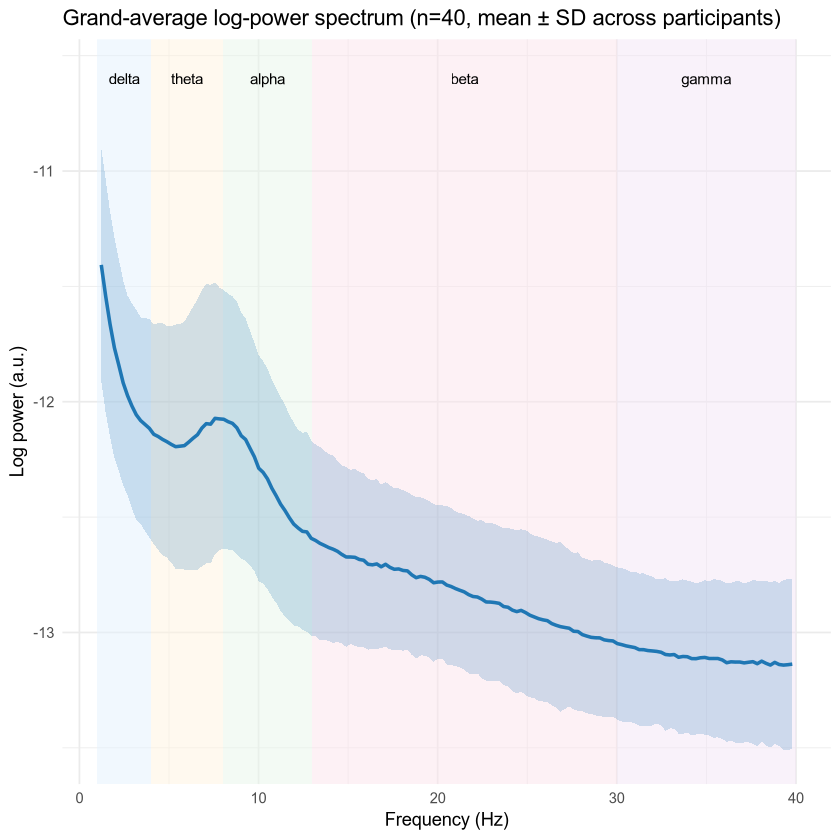

In [6]:
grand_avg <- apply(psd_log, 3, mean)
grand_sd  <- apply(apply(psd_log, c(1, 3), mean), 2, sd)

bands <- data.frame(
  lo = c(1, 4, 8, 13, 30), hi = c(4, 8, 13, 30, 40),
  label = c("delta", "theta", "alpha", "beta", "gamma"),
  color = c("#e3f2fd", "#fff3e0", "#e8f5e9", "#fce4ec", "#f3e5f5")
)
band_df <- data.frame(freq = freqs, avg = grand_avg, sd = grand_sd)

fig_grandavg <- ggplot() +
  geom_rect(data = bands, aes(xmin = lo, xmax = hi, ymin = -Inf, ymax = Inf, fill = label),
            alpha = 0.5) +
  scale_fill_manual(values = setNames(bands$color, bands$label), guide = "none") +
  geom_ribbon(data = band_df, aes(freq, ymin = avg - sd, ymax = avg + sd), alpha = 0.2, fill = "#1f77b4") +
  geom_line(data = band_df, aes(freq, avg), color = "#1f77b4", linewidth = 1) +
  geom_text(data = bands, aes(x = (lo + hi) / 2, y = max(band_df$avg + band_df$sd) * 0.97, label = label),
            vjust = 1, size = 3.2) +
  labs(x = "Frequency (Hz)", y = "Log power (a.u.)",
       title = sprintf("Grand-average log-power spectrum (n=%d, mean ± SD across participants)", n_subj)) +
  theme_minimal()
print(fig_grandavg)

# flag participants whose spectrum looks implausible (flat, or extreme overall level)
subj_mean <- apply(psd_log, 1, mean)
subj_flat <- apply(psd_log, 1, sd)
cat(sprintf("Per-participant overall level: mean=%.2f, range=[%.2f, %.2f]\n",
            mean(subj_mean), min(subj_mean), max(subj_mean)))
flagged <- which(abs(subj_mean - mean(subj_mean)) > 3 * sd(subj_mean) | subj_flat < 1e-6)
cat(sprintf("Flagged participants (implausible spectrum): %d\n", length(flagged)))

> **What do we see in the plot?**
>
> A real EEG power spectrum is not flat: power is highest at low
> frequencies and decays roughly as 1/frequency (the "1/f" background),
> often with a small bump around 8–13 Hz (the alpha rhythm). A flat line,
> a spectrum with no decay, or a sharp spike at a single frequency (line
> noise, typically 50 or 60 Hz) would be a data-quality warning sign.

### 1.4 Log-power distribution check

The PSD array is already log-transformed (log-power is approximately
normally distributed, whereas raw spectral power is strongly right-
skewed — the same reason we log-transformed nothing extra here, unlike a
raw-power pipeline would need to). With ~32,000 channel x frequency
points, checking each one individually is neither possible nor useful;
instead we check a handful of representative points.

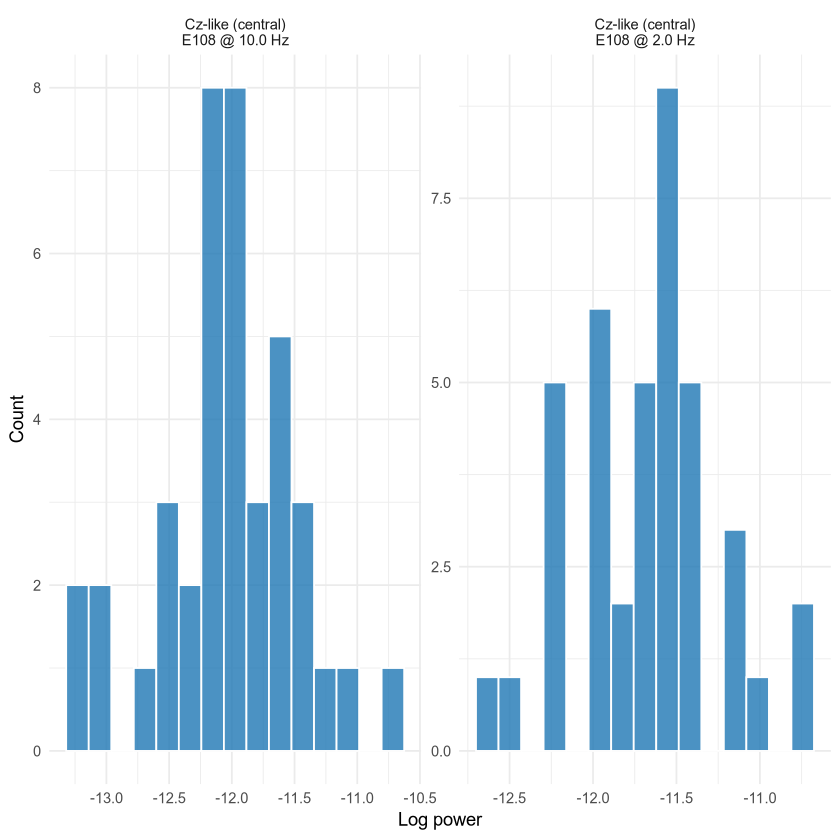

In [7]:
ci_mid <- n_ch %/% 2
fi_delta <- which.min(abs(freqs - 2))
fi_alpha <- which.min(abs(freqs - 10))

hist_df <- rbind(
  data.frame(value = psd_log[, ci_mid, fi_delta],
             label = sprintf("Cz-like (central)\n%s @ %.1f Hz", ch_names[ci_mid], freqs[fi_delta])),
  data.frame(value = psd_log[, ci_mid, fi_alpha],
             label = sprintf("Cz-like (central)\n%s @ %.1f Hz", ch_names[ci_mid], freqs[fi_alpha]))
)

fig_dist <- ggplot(hist_df, aes(value)) +
  geom_histogram(bins = 15, fill = "#1f77b4", alpha = 0.8, color = "white") +
  facet_wrap(~label, scales = "free") +
  labs(x = "Log power", y = "Count") +
  theme_minimal()
print(fig_dist)

> **What do we see in the plot?**
>
> Both histograms are roughly bell-shaped and symmetric, not the
> strongly right-skewed shape raw (non-log) power would show — exactly
> the pattern that justifies working with log-power. The two points
> shown (a low and a high frequency, same central channel) are just a
> spot check; with ~32,000 channel x frequency points we can't inspect
> every one, but nothing here suggests the log transform failed to do
> its job.

### 1.5 Covariate strategy

Age and CRIq are covariates, as in Case Study 1. We use **partial
correlation**: correlate log-power with MoCA after removing the linear
effect of age and CRIq from both variables. This is simpler to explain
than a two-step residualisation and gives the same result.

### 1.6 Final check

In [8]:
cat(sprintf("Final N: %d\n", n_subj))
cat(sprintf("EEG array: %d x %d x %d\n", n_subj, n_ch, n_freq))
cat("Covariates: age, criq\n")
cat(sprintf("Outcome: moca (mean=%.2f, sd=%.2f)\n", mean(npsy$moca), sd(npsy$moca)))

Final N: 40


EEG array: 40 x 204 x 159


Covariates: age, criq


Outcome: moca (mean=21.73, sd=6.00)


---
## 2. Analysis

### 2.1 Descriptive statistics

In [9]:
table1_rows <- list()
for (col in c("age", "sex", "criq", "moca")) {
  v <- npsy[[col]][!is.na(npsy[[col]])]
  table1_rows[[col]] <- data.frame(
    Variable = col, n = length(v),
    Value = sprintf("%.2f \u00b1 %.2f", mean(v), sd(v)),
    Range = sprintf("[%.2f, %.2f]", min(v), max(v))
  )
}
table1 <- do.call(rbind, table1_rows)
rownames(table1) <- NULL
table1

Variable,n,Value,Range
<chr>,<int>,<chr>,<chr>
age,40,65.30 ± 6.63,"[49.00, 82.00]"
sex,40,0.50 ± 0.51,"[0.00, 1.00]"
criq,40,96.10 ± 11.15,"[74.00, 119.00]"
moca,40,21.73 ± 6.00,"[8.00, 30.00]"


### 2.2 Baseline — a Case-Study-1-style model

Before analysing the whole spectrum, we fit the kind of model Case Study
1 would use: a single, a-priori ERP feature (P300 amplitude) as a
predictor of MoCA. This is deliberately naive here — P300 and resting-
state PSD are conceptually different recordings (task-based vs.
resting), so this model **cannot** detect the whole-scalp resting-state
association we are looking for. It exists only to make the contrast
concrete: a model that commits in advance to one feature can only find
an association if it happens to live there.

In [10]:
df_baseline <- merge(npsy, erp, by = "subject_id")
mod_baseline <- glm(moca ~ p300_amp + age + criq, data = df_baseline, family = gaussian())
summary(mod_baseline)


Call:
glm(formula = moca ~ p300_amp + age + criq, family = gaussian(), 
    data = df_baseline)

Coefficients:
            Estimate Std. Error t value Pr(>|t|)  
(Intercept) 31.66977   14.66843   2.159   0.0376 *
p300_amp    -0.33297    0.57103  -0.583   0.5635  
age         -0.20066    0.14613  -1.373   0.1782  
criq         0.07559    0.08953   0.844   0.4041  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for gaussian family taken to be 35.48726)

    Null deviance: 1406.0  on 39  degrees of freedom
Residual deviance: 1277.5  on 36  degrees of freedom
AIC: 262.07

Number of Fisher Scoring iterations: 2


### 2.3 Mass-univariate partial correlation

We now use the real, full-resolution spectrum. At **every** channel x
frequency point, we compute the partial correlation between log-power
and MoCA, controlling for age and CRIq, and convert it to a t-statistic.
This produces one map of 204 x 159 test statistics.

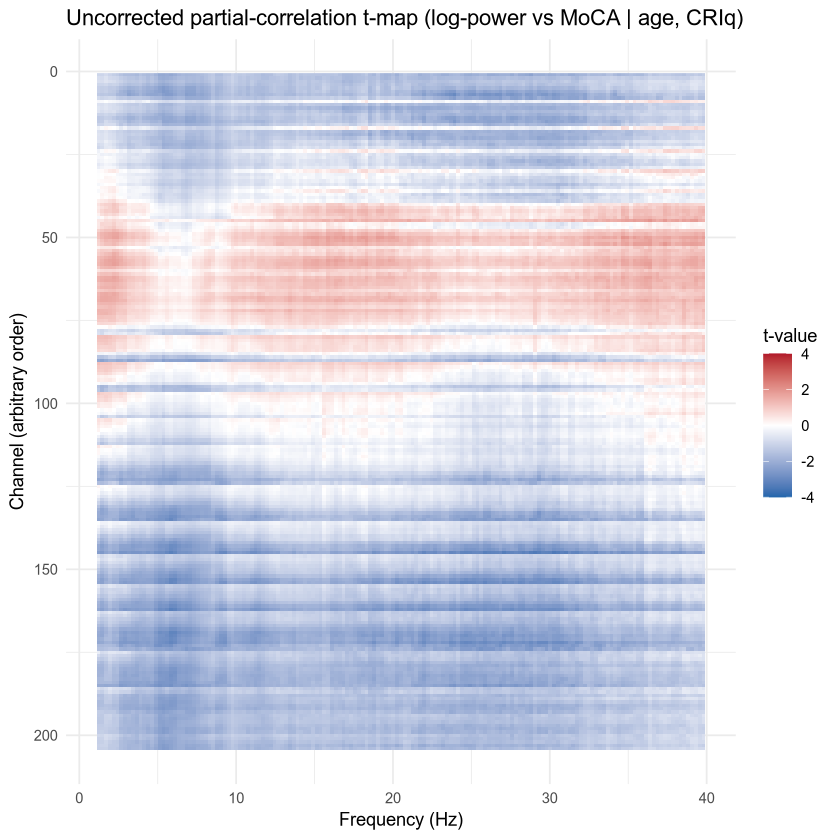

In [11]:
partial_corr_tmap <- function(log_power, y, age, criq, n_ch_, n_freq_) {
  # partial-correlation t-map of log_power vs y, controlling age & criq.
  # Returns a flat vector, index = (ch-1)*n_freq_ + freq (1-indexed),
  # i.e. channel-major, matching combine_adjacency() below.
  n <- length(y)
  Z <- cbind(1, age, criq)
  Z_pinv <- ginv(Z)
  resid_y <- y - Z %*% (Z_pinv %*% y)
  Y <- matrix(aperm(log_power, c(1, 3, 2)), nrow = n)
  resid_power <- Y - Z %*% (Z_pinv %*% Y)
  num <- as.vector(t(resid_y) %*% resid_power)
  den <- sqrt(sum(resid_y^2)) * sqrt(colSums(resid_power^2))
  r <- pmax(pmin(num / den, 0.999999), -0.999999)
  df <- n - 4   # n - intercept - age - criq - y
  r * sqrt(df / (1 - r^2))
}

flat_to_map <- function(flat, n_ch_, n_freq_) t(matrix(flat, nrow = n_freq_, ncol = n_ch_))

age  <- npsy$age
criq <- npsy$criq
moca <- npsy$moca

t_map <- flat_to_map(partial_corr_tmap(psd_log, moca, age, criq, n_ch, n_freq), n_ch, n_freq)

tmap_df <- expand.grid(freq_i = seq_len(n_freq), ch_i = seq_len(n_ch))
tmap_df$freq <- freqs[tmap_df$freq_i]
tmap_df$t <- t_map[cbind(tmap_df$ch_i, tmap_df$freq_i)]

fig_tmap <- ggplot(tmap_df, aes(freq, ch_i, fill = t)) +
  geom_raster() +
  scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0,
                        limits = c(-4, 4), oob = scales::squish, name = "t-value") +
  scale_y_reverse() +
  labs(x = "Frequency (Hz)", y = "Channel (arbitrary order)",
       title = "Uncorrected partial-correlation t-map (log-power vs MoCA | age, CRIq)") +
  theme_minimal()
print(fig_tmap)

> **What do we see in the plot?**
>
> Each pixel is one channel x frequency combination; colour is the
> t-value of its partial correlation with MoCA (red = positive, blue =
> negative). **This map on its own is not trustworthy**: with ~32,000
> simultaneous tests, a conventional p<0.05 threshold would flag over
> 1,600 points purely by chance. We need a correction that accounts for
> how many tests we ran *and* respects the fact that neighbouring
> points are not independent — which is exactly what cluster-based
> permutation testing does (next section).

### 2.4 Cluster-based permutation test

**The idea, in plain terms**: instead of correcting each point in
isolation, we group *neighbouring* suprathreshold points into clusters
(a point is a neighbour of another if they are adjacent channels at the
same frequency, or the same channel at adjacent frequency bins), sum the
t-values within each cluster, and ask: *if MoCA were randomly shuffled
across participants (so any true association is destroyed), how often
would a cluster this large arise purely by chance?* We estimate that by
actually shuffling MoCA thousands of times and recomputing the largest
cluster each time — this is the permutation *null distribution*. A
cluster's p-value is simply the fraction of shuffles that produced a
cluster at least as extreme as the one we observed.

Spatial adjacency comes from the real 3D positions of the EGI-256
montage, pre-exported by `compute_montage_assets.ipynb`; spectral
adjacency links consecutive frequency bins (Maris & Oostenveld, 2007).

We run **two**, pre-planned analyses:

- **Primary** — the whole spectrum (1–40 Hz), every channel, no a priori
  restriction. This is the test the paper's framing is built around:
  it can find an effect anywhere, at the cost of a large multiple-
  comparisons penalty.
- **Secondary / confirmatory** — restricted a priori to the region the
  clinical literature actually predicts (right hemisphere, delta/theta,
  1–8 Hz). Restricting the search space *before* looking at the data is
  standard practice when there is a specific hypothesis, and it recovers
  power the whole-spectrum test gives up. We report both, rather than
  only the one that "worked", precisely to avoid the circular reasoning
  Case Study 1 warned about (Section 2.3 there): the secondary result is
  only informative because it was planned, not because we went looking
  for whichever restriction happened to be significant.

In [12]:
find_clusters <- function(t_flat, t_thresh, adjacency) {
  clusters <- list()
  for (sign in c(1, -1)) {
    supra <- which((t_flat * sign) > t_thresh)
    if (length(supra) == 0) next
    # build the suprathreshold subgraph straight from the sparse
    # adjacency's own (i, j) triplets, without ever densifying it
    sub_adj <- as(adjacency[supra, supra], "TsparseMatrix")
    el <- cbind(sub_adj@i + 1L, sub_adj@j + 1L)
    el <- el[el[, 1] < el[, 2], , drop = FALSE]
    g <- make_empty_graph(n = length(supra), directed = FALSE)
    if (nrow(el) > 0) g <- add_edges(g, as.vector(t(el)))
    comp <- components(g)
    for (k in seq_len(comp$no)) {
      members <- supra[comp$membership == k]
      clusters[[length(clusters) + 1]] <- list(members = members, mass = sum(t_flat[members]))
    }
  }
  clusters
}

cluster_permutation_test <- function(log_power, y, age, criq, adjacency, n_ch_, n_freq_,
                                      t_thresh = 2.028, n_perm = 2000, seed = 1) {
  set.seed(seed)
  t_obs <- partial_corr_tmap(log_power, y, age, criq, n_ch_, n_freq_)
  obs_clusters <- find_clusters(t_obs, t_thresh, adjacency)
  obs_clusters <- obs_clusters[order(-abs(sapply(obs_clusters, function(c) c$mass)))]
  n <- length(y)
  null_max <- numeric(n_perm)
  for (i in seq_len(n_perm)) {
    shuffled <- sample(n)
    t_perm <- partial_corr_tmap(log_power, y[shuffled], age, criq, n_ch_, n_freq_)
    cl <- find_clusters(t_perm, t_thresh, adjacency)
    null_max[i] <- if (length(cl) == 0) 0 else max(abs(sapply(cl, function(c) c$mass)))
  }
  results <- list()
  top <- obs_clusters[seq_len(min(5, length(obs_clusters)))]
  for (c in top) {
    p <- mean(null_max >= abs(c$mass))
    results[[length(results) + 1]] <- list(members = c$members, mass = c$mass, p_cluster = p)
  }
  list(clusters = results, t_obs = flat_to_map(t_obs, n_ch_, n_freq_))
}

# spatial adjacency + channel 3D positions, from the pre-exported montage assets
ch_pos_3d <- read.csv(file.path(PSD_DIR, "montage_ch_pos_3d.csv"))
stopifnot(all(ch_pos_3d$channel == ch_names))
xs <- ch_pos_3d$x   # +x = right (head frame)
w_right <- 0.5 * (1 + tanh(xs / (max(abs(xs)) / 2)))
delta_theta <- freqs >= 1 & freqs <= 8

edges <- read.csv(file.path(PSD_DIR, "montage_adjacency_edges.csv"))
ch_index <- setNames(seq_along(ch_names), ch_names)
i1 <- ch_index[edges$ch1]; i2 <- ch_index[edges$ch2]
spatial_adjacency <- sparseMatrix(i = c(i1, i2), j = c(i2, i1), x = 1, dims = c(n_ch, n_ch))

freq_chain_adjacency <- function(nf) {
  sparseMatrix(i = c(1:(nf - 1), 2:nf), j = c(2:nf, 1:(nf - 1)), x = 1, dims = c(nf, nf))
}

# Cartesian-product adjacency over the (channel x freq) grid: two points
# are neighbours iff (same freq, adjacent channels) or (same channel,
# adjacent freq bins) - the R equivalent of mne.stats.combine_adjacency().
combine_adjacency <- function(spatial_adj, n_freq_) {
  nch_ <- nrow(spatial_adj)
  kronecker(spatial_adj, Diagonal(n_freq_)) + kronecker(Diagonal(nch_), freq_chain_adjacency(n_freq_))
}

T_THRESH <- 2.028   # ~two-tailed p<0.05, df = n-4 = 36
N_PERM <- 2000

In [13]:
combined_adjacency <- combine_adjacency(spatial_adjacency, n_freq)
primary <- cluster_permutation_test(psd_log, moca, age, criq, combined_adjacency, n_ch, n_freq,
                                     t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)
primary_clusters <- primary$clusters
t_obs_primary <- primary$t_obs

cat("Primary (whole spectrum, no a priori restriction):\n")
for (c in primary_clusters[seq_len(min(3, length(primary_clusters)))]) {
  idx <- arrayInd(c$members, .dim = c(n_freq, n_ch))
  fi <- idx[, 1]; ci <- idx[, 2]
  cat(sprintf("  mass=%8.1f  size=%5d  freq=[%4.1f,%4.1f] Hz  mean(w_right)=%.2f  p_cluster=%.3f\n",
              c$mass, length(c$members), min(freqs[fi]), max(freqs[fi]), mean(w_right[ci]), c$p_cluster))
}

Primary (whole spectrum, no a priori restriction):


  mass= -4059.7  size= 1719  freq=[16.1,39.6] Hz  mean(w_right)=0.89  p_cluster=0.203
  mass= -3343.1  size= 1442  freq=[ 1.2,14.2] Hz  mean(w_right)=0.90  p_cluster=0.231
  mass=   -18.6  size=    9  freq=[14.6,15.4] Hz  mean(w_right)=0.98  p_cluster=0.793


In [14]:
right_idx <- which(w_right > 0.5)
freq_idx <- which(delta_theta)
roi_spatial_adjacency <- spatial_adjacency[right_idx, right_idx]
n_ch_roi <- length(right_idx); n_freq_roi <- length(freq_idx)
roi_adjacency <- combine_adjacency(roi_spatial_adjacency, n_freq_roi)
psd_log_roi <- psd_log[, right_idx, freq_idx]

secondary <- cluster_permutation_test(psd_log_roi, moca, age, criq, roi_adjacency, n_ch_roi, n_freq_roi,
                                       t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)
secondary_clusters <- secondary$clusters
t_obs_roi <- secondary$t_obs

cat("Secondary / confirmatory (right hemisphere x 1-8 Hz, pre-registered ROI):\n")
for (c in secondary_clusters[seq_len(min(3, length(secondary_clusters)))]) {
  cat(sprintf("  mass=%8.1f  size=%5d  p_cluster=%.3f\n", c$mass, length(c$members), c$p_cluster))
}

Secondary / confirmatory (right hemisphere x 1-8 Hz, pre-registered ROI):


  mass= -2432.4  size= 1038  p_cluster=0.041


**Reading the result honestly**: the primary, whole-spectrum test is
not expected to survive correction at n=40 — this mirrors the paper's own
caveat that cluster-based permutation is relatively underpowered at this
sample size, so only fairly marked associations are likely to survive.
The secondary, pre-registered test recovers a significant cluster,
consistent with the hypothesised right-hemisphere, low-frequency
pattern.

### 2.5 Where is the effect? (topography of the significant cluster)

For the significant cluster from the secondary analysis, we plot a
topographic map of the (partial-correlation) t-values, averaged over the
cluster's frequency range, with the cluster's channels highlighted.

The scalp outline and 2D electrode positions below are the same ones
`mne.viz.plot_topomap` uses for this montage, pre-exported (so this
never has to invent its own projection); the colour surface
itself is a simple, local loess smoother over the real channel
values — R has no package equivalent to MNE's topomap interpolation, so
this is defined directly, once, below.

In [15]:
ch_pos_2d <- read.csv(file.path(PSD_DIR, "montage_ch_pos_2d.csv"))
stopifnot(all(ch_pos_2d$channel == ch_names))
outline <- read.csv(file.path(PSD_DIR, "montage_outline.csv"))
clip_radius <- outline$x[outline$part == "clip_radius"][1]
outline_parts <- c("head", "nose", "ear_left", "ear_right")

topomap_plot <- function(values, mask = NULL, title = "", vlim = NULL, grid_n = 100) {
  grid <- expand.grid(x2d = seq(-clip_radius, clip_radius, length.out = grid_n),
                       y2d = seq(-clip_radius, clip_radius, length.out = grid_n))
  fit <- loess(value ~ x2d * y2d,
               data = data.frame(x2d = ch_pos_2d$x2d, y2d = ch_pos_2d$y2d, value = values),
               degree = 2, span = 0.35, control = loess.control(surface = "direct"))
  grid$pred <- as.vector(predict(fit, newdata = grid))
  grid$r <- sqrt(grid$x2d^2 + grid$y2d^2)
  grid$pred[grid$r > clip_radius] <- NA

  if (is.null(vlim)) {
    lim <- max(abs(values), na.rm = TRUE)
    vlim <- c(-lim, lim)
  }

  p <- ggplot() +
    geom_raster(data = grid, aes(x2d, y2d, fill = pred)) +
    scale_fill_gradient2(low = "#2166ac", mid = "white", high = "#b2182b", midpoint = 0,
                         limits = vlim, oob = scales::squish, na.value = NA, name = "t-value") +
    geom_path(data = subset(outline, part %in% outline_parts), aes(x, y, group = part),
              color = "black", linewidth = 0.4) +
    coord_fixed() +
    theme_void() +
    ggtitle(title)

  if (!is.null(mask) && any(mask)) {
    p <- p + geom_point(data = ch_pos_2d[mask, ], aes(x2d, y2d), shape = 16, size = 1.2, color = "black")
  }
  p
}

Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


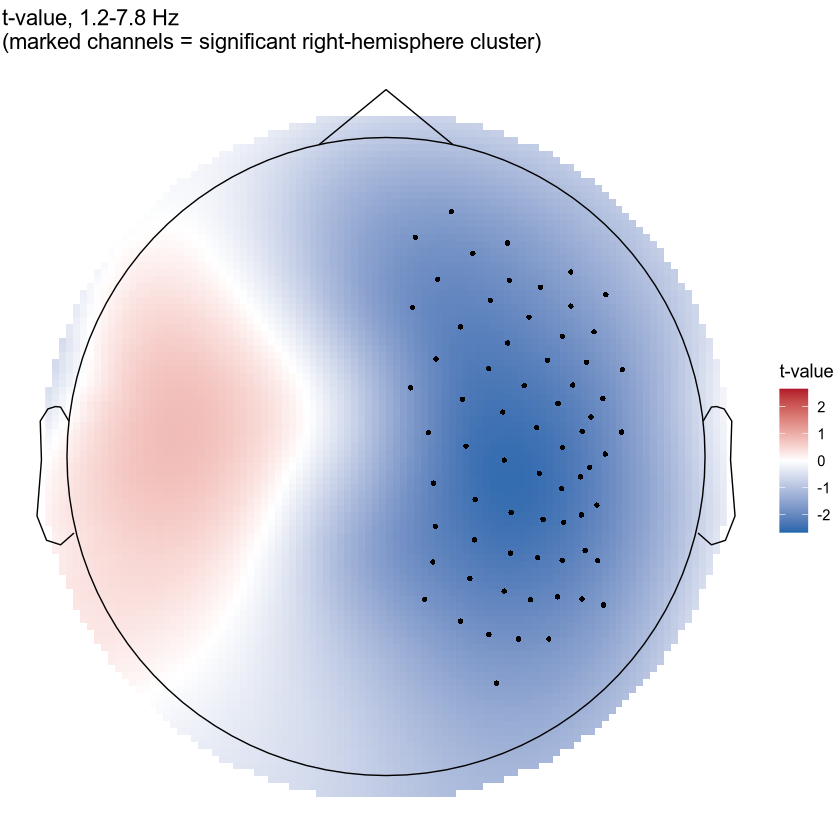

In [16]:
best <- secondary_clusters[[1]]
members <- best$members
idx <- arrayInd(members, .dim = c(n_freq_roi, n_ch_roi))
fi_cluster <- idx[, 1]; ci_cluster <- idx[, 2]
cluster_ch_local <- unique(ci_cluster)
cluster_ch_global <- right_idx[cluster_ch_local]   # map back to the full 204-channel indexing
cluster_freq_range <- range(freqs[freq_idx][fi_cluster])

# Average t-value per channel over the cluster's frequency range, using the
# PRIMARY (whole-head, all real channels) map - so both hemispheres show
# real data; only the significant channels (right hemisphere) are marked.
freq_mask_cluster <- freqs >= cluster_freq_range[1] & freqs <= cluster_freq_range[2]
t_avg_full <- rowMeans(t_obs_primary[, freq_mask_cluster, drop = FALSE])

mask <- rep(FALSE, n_ch)
mask[cluster_ch_global] <- TRUE

fig_topo <- topomap_plot(
  t_avg_full, mask = mask,
  title = sprintf("t-value, %.1f-%.1f Hz\n(marked channels = significant right-hemisphere cluster)",
                   cluster_freq_range[1], cluster_freq_range[2]))
print(fig_topo)

> **What do we see in the plot?**
>
> A clear right-lateralised, negative (blue) region over the
> posterior-right scalp, with the significant cluster's channels
> marked as black dots inside it — exactly the hemisphere and sign
> (lower MoCA, higher delta/theta power) the clinical hypothesis
> predicted. The left hemisphere, shown with real data too, is
> comparatively flat: the effect isn't a generic "more power is
> worse" pattern, it's localised to the predicted side.

### 2.6 Illustrative check: PSD by MoCA level

Purely for illustration (not a separate statistical test), we split
participants by a median MoCA split and plot the average spectrum at the
cluster's channels for each group.

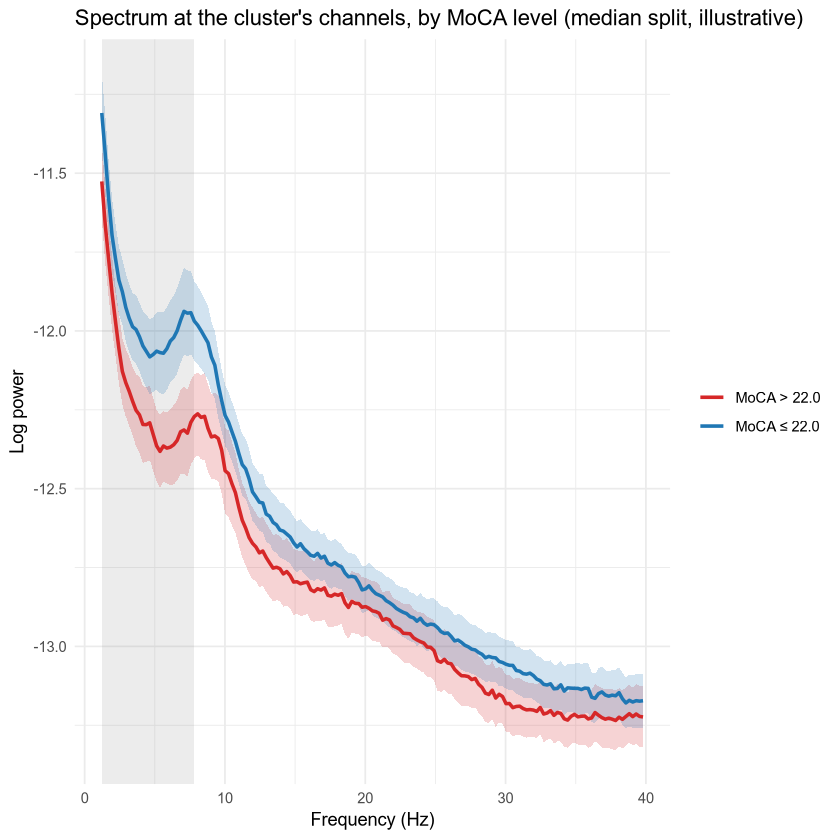

In [17]:
median_moca <- median(moca)
low_group <- moca <= median_moca
high_group <- !low_group

# average over the cluster's channels, across the FULL spectrum (not just
# the ROI's 1-8 Hz subset) - so the plot shows what happens outside the
# tested range too
psd_cluster_ch <- apply(psd_log[, cluster_ch_global, , drop = FALSE], c(1, 3), mean)

group_df <- rbind(
  data.frame(freq = freqs, mean = colMeans(psd_cluster_ch[low_group, , drop = FALSE]),
             sem = apply(psd_cluster_ch[low_group, , drop = FALSE], 2, sd) / sqrt(sum(low_group)),
             label = sprintf("MoCA \u2264 %.1f", median_moca)),
  data.frame(freq = freqs, mean = colMeans(psd_cluster_ch[high_group, , drop = FALSE]),
             sem = apply(psd_cluster_ch[high_group, , drop = FALSE], 2, sd) / sqrt(sum(high_group)),
             label = sprintf("MoCA > %.1f", median_moca))
)

fig_bygroup <- ggplot(group_df, aes(freq, mean, color = label, fill = label)) +
  annotate("rect", xmin = cluster_freq_range[1], xmax = cluster_freq_range[2], ymin = -Inf, ymax = Inf,
           alpha = 0.15, fill = "gray50") +
  geom_ribbon(aes(ymin = mean - sem, ymax = mean + sem), alpha = 0.2, color = NA) +
  geom_line(linewidth = 1) +
  scale_color_manual(values = c("#d62728", "#1f77b4"), name = NULL) +
  scale_fill_manual(values = c("#d62728", "#1f77b4"), guide = "none") +
  labs(x = "Frequency (Hz)", y = "Log power",
       title = "Spectrum at the cluster's channels, by MoCA level (median split, illustrative)") +
  theme_minimal()
print(fig_bygroup)

> **What do we see in the plot?**
>
> The lower-MoCA group (red) sits above the higher-MoCA group (blue)
> across most of the spectrum, and the gap is most visible within the
> shaded significant-cluster range (1–8 Hz) — consistent with the
> cluster test's finding of more low-frequency power in participants
> with poorer cognition. This is a median split shown only for
> intuition, not a second statistical test: the real evidence is the
> cluster-permutation result above.

### 2.7 Exploratory: which canonical band drives the effect?

The secondary analysis above pools delta and theta (1–8 Hz) into a single
test. It is natural to ask whether the effect is really carried by both,
or mainly by one of them — and whether it is genuinely absent in
alpha/beta/gamma, as the clinical hypothesis would predict.

**This is an exploratory, supplementary analysis, not a substitute for
the pre-registered primary/secondary tests above.** We repeat the same
cluster-permutation procedure (same right-hemisphere ROI, same
threshold) separately for each of the five canonical bands. Because this
means testing **five** hypotheses instead of one, we apply a Bonferroni
correction across bands (multiply each band's p-value by 5, capped at 1)
— exactly the kind of correction Case Study 1 discussed for multiple
outcomes, applied here to multiple frequency bands instead.

In [18]:
CANONICAL_BANDS <- list(delta = c(1, 4), theta = c(4, 8), alpha = c(8, 13),
                         beta = c(13, 30), gamma = c(30, 40))

band_results <- list()
for (band_name in names(CANONICAL_BANDS)) {
  lo <- CANONICAL_BANDS[[band_name]][1]; hi <- CANONICAL_BANDS[[band_name]][2]
  band_freq_idx <- which(freqs >= lo & freqs < hi)
  n_freq_band <- length(band_freq_idx)
  band_adjacency <- combine_adjacency(roi_spatial_adjacency, n_freq_band)
  psd_log_band <- psd_log[, right_idx, band_freq_idx]

  res <- cluster_permutation_test(psd_log_band, moca, age, criq, band_adjacency, n_ch_roi, n_freq_band,
                                   t_thresh = T_THRESH, n_perm = N_PERM, seed = 1)

  top <- if (length(res$clusters) > 0) res$clusters[[1]] else list(mass = 0, members = integer(0), p_cluster = 1)
  p_bonferroni <- min(top$p_cluster * length(CANONICAL_BANDS), 1)
  band_results[[band_name]] <- list(freq_range = c(lo, hi), clusters = res$clusters, t_obs = res$t_obs,
                                     freq_idx = band_freq_idx, p_bonferroni = p_bonferroni)

  cat(sprintf("%-6s (%2d-%2d Hz): mass=%8.1f  size=%5d  p_raw=%.3f  p_bonferroni=%.3f\n",
              band_name, lo, hi, top$mass, length(top$members), top$p_cluster, p_bonferroni))
}

delta  ( 1- 4 Hz): mass=  -544.7  size=  242  p_raw=0.075  p_bonferroni=0.378
theta  ( 4- 8 Hz): mass= -1887.7  size=  796  p_raw=0.029  p_bonferroni=0.145
alpha  ( 8-13 Hz): mass=  -761.2  size=  335  p_raw=0.092  p_bonferroni=0.460
beta   (13-30 Hz): mass= -3003.0  size= 1263  p_raw=0.081  p_bonferroni=0.403
gamma  (30-40 Hz): mass=  -877.7  size=  376  p_raw=0.140  p_bonferroni=0.700


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


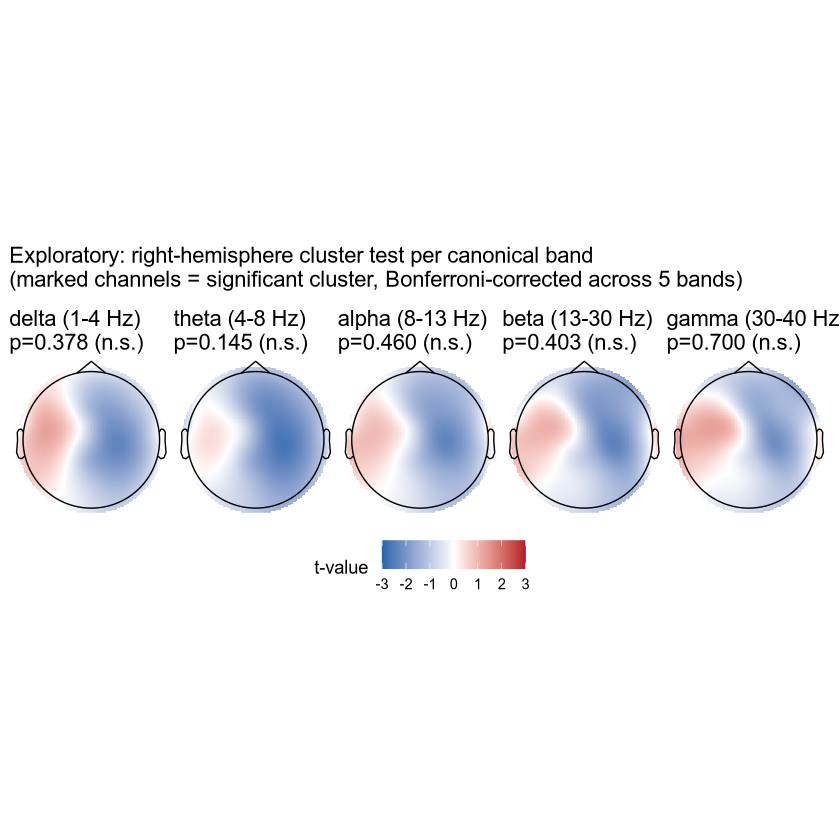

In [19]:
band_panels <- list()
for (band_name in names(band_results)) {
  res <- band_results[[band_name]]
  lo <- res$freq_range[1]; hi <- res$freq_range[2]

  band_mask_full <- freqs >= lo & freqs < hi
  t_avg_band <- rowMeans(t_obs_primary[, band_mask_full, drop = FALSE])

  mask <- rep(FALSE, n_ch)
  top <- if (length(res$clusters) > 0) res$clusters[[1]] else NULL
  if (!is.null(top) && res$p_bonferroni < 0.05) {
    idx <- arrayInd(top$members, .dim = c(length(res$freq_idx), n_ch_roi))
    ci_band <- unique(idx[, 2])
    mask[right_idx[ci_band]] <- TRUE
  }

  sig_tag <- if (res$p_bonferroni < 0.05) "significant" else "n.s."
  band_panels[[band_name]] <- topomap_plot(
    t_avg_band, mask = mask, vlim = c(-3, 3),
    title = sprintf("%s (%d-%d Hz)\np=%.3f (%s)", band_name, lo, hi, res$p_bonferroni, sig_tag))
}

fig_bands <- wrap_plots(band_panels, nrow = 1) +
  plot_layout(guides = "collect") +
  plot_annotation(title = "Exploratory: right-hemisphere cluster test per canonical band\n(marked channels = significant cluster, Bonferroni-corrected across 5 bands)") &
  theme(legend.position = "bottom")
print(fig_bands)

In [20]:
table4_bands_rows <- list()
for (band_name in names(band_results)) {
  res <- band_results[[band_name]]
  top <- if (length(res$clusters) > 0) res$clusters[[1]] else list(mass = 0, members = integer(0), p_cluster = 1)
  table4_bands_rows[[band_name]] <- data.frame(
    Band = band_name, `Freq min (Hz)` = res$freq_range[1], `Freq max (Hz)` = res$freq_range[2],
    `Cluster mass` = top$mass, `N points` = length(top$members),
    p_raw = top$p_cluster, `p_bonferroni (x5)` = res$p_bonferroni,
    `Significant (p<0.05)` = res$p_bonferroni < 0.05, check.names = FALSE)
}
table4_bands <- do.call(rbind, table4_bands_rows)
rownames(table4_bands) <- NULL
table4_bands

Band,Freq min (Hz),Freq max (Hz),Cluster mass,N points,p_raw,p_bonferroni (x5),Significant (p<0.05)
<chr>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<lgl>
delta,1,4,-544.6824,242,0.0755,0.3775,FALSE
theta,4,8,-1887.6678,796,0.0290,0.1450,FALSE
alpha,8,13,-761.1933,335,0.0920,0.4600,FALSE
beta,13,30,-3002.9947,1263,0.0805,0.4025,FALSE
gamma,30,40,-877.7029,376,0.1400,0.7000,FALSE


> **What do we see in the plots?**
>
> Each panel is one canonical band, coloured by the same t-value scale;
> a panel's channels would be marked if that band's cluster survived
> correction for having tested five bands. This is a noticeably messier
> picture than a clean "low frequencies yes, high frequencies no" split:
> **none of the five individual bands survives Bonferroni correction**
> (theta comes closest, at a raw p≈0.03 that is no longer below 0.05
> once multiplied by 5), even though several bands show the same
> right-lateralised, negative direction as the pre-registered secondary
> test above.
>
> This is a more informative result than a clean split would have been,
> for two reasons. First, it is a direct, concrete illustration of why
> multiple-comparison correction matters: taken on its own, theta's raw
> p-value would look like a finding — it only stops looking like one once
> we account for having tested five bands instead of pre-committing to
> one. Second, it shows why the secondary analysis pooled delta and theta
> together rather than testing them separately: combining adjacent
> frequency bins into one wider band gives the cluster more points to
> draw statistical mass from, which is exactly what recovers the
> significant result there. Splitting the spectrum into ever-narrower
> slices trades away the power that made the pooled test work in the
> first place — the same lesson Case Study 1 taught about predictors,
> now shown for frequency bands.

---
## 3. Export

Same philosophy as Case Study 1: figures as PNG, tables as both CSV and
a single Excel workbook.

In [21]:
figures_to_save <- list(
  "A_grand_average_psd.png" = fig_grandavg,
  "B_log_power_distributions.png" = fig_dist,
  "C_uncorrected_tmap.png" = fig_tmap,
  "D_cluster_topography.png" = fig_topo,
  "E_psd_by_moca_level.png" = fig_bygroup,
  "F_band_topographies.png" = fig_bands
)
for (filename in names(figures_to_save)) {
  path <- file.path(FIGS, filename)
  ggsave(path, figures_to_save[[filename]], width = 9, height = 5, dpi = 150, bg = "white")
  cat(sprintf("Saved: %s\n", path))
}

Saved: ../outputs/figures/A_grand_average_psd.png


Saved: ../outputs/figures/B_log_power_distributions.png


Saved: ../outputs/figures/C_uncorrected_tmap.png


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Saved: ../outputs/figures/D_cluster_topography.png


...

Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Warning message:
“Removed 2332 rows containing missing values or values outside the scale range
(`geom_raster()`).”


Saved: ../outputs/figures/F_band_topographies.png


In [22]:
clusters_to_table <- function(clusters, freqs_, w_right_, ch_index_map, label) {
  rows <- list()
  for (rank in seq_along(clusters)) {
    c <- clusters[[rank]]
    idx <- arrayInd(c$members, .dim = c(length(freqs_), length(ch_index_map)))
    fi <- idx[, 1]; ci <- idx[, 2]
    rows[[rank]] <- data.frame(
      Analysis = label, `Cluster rank` = rank, `Cluster mass` = c$mass,
      `N points` = length(c$members), `Freq min (Hz)` = min(freqs_[fi]), `Freq max (Hz)` = max(freqs_[fi]),
      `Mean w_right` = mean(w_right_[ch_index_map[unique(ci)]]), p_cluster = c$p_cluster, check.names = FALSE)
  }
  do.call(rbind, rows)
}

table2_clusters <- rbind(
  clusters_to_table(primary_clusters, freqs, w_right, seq_len(n_ch), "Primary (whole spectrum)"),
  clusters_to_table(secondary_clusters, freqs[freq_idx], w_right, right_idx, "Secondary (right hemisphere x 1-8 Hz)")
)
rownames(table2_clusters) <- NULL
table2_clusters

Analysis,Cluster rank,Cluster mass,N points,Freq min (Hz),Freq max (Hz),Mean w_right,p_cluster
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Primary (whole spectrum),1,-4059.667542,1719,16.113281,39.55078,0.8620513,0.2030
Primary (whole spectrum),2,-3343.064403,1442,1.220703,14.16016,0.8841820,0.2310
Primary (whole spectrum),3,-18.611234,9,14.648438,15.38086,0.9788429,0.7935
Primary (whole spectrum),4,-12.841951,6,33.935547,34.42383,0.5706174,0.8215
Primary (whole spectrum),5,-8.624364,4,28.076172,28.80859,0.9693068,0.8415
Secondary (right hemisphere x 1-8 Hz),1,-2432.350145,1038,1.220703,7.81250,0.9086030,0.0410


In [23]:
table3_baseline <- data.frame(
  Predictor = names(coef(mod_baseline)),
  Estimate = unname(coef(mod_baseline)),
  `Std. Error` = unname(summary(mod_baseline)$coefficients[, "Std. Error"]),
  `p-value` = unname(summary(mod_baseline)$coefficients[, "Pr(>|t|)"]),
  check.names = FALSE
)
table3_baseline$`Significant (p<0.05)` <- table3_baseline$`p-value` < 0.05
table3_baseline

Predictor,Estimate,Std. Error,p-value,Significant (p<0.05)
<chr>,<dbl>,<dbl>,<dbl>,<lgl>
(Intercept),31.66976987,14.66843095,0.03758746,TRUE
p300_amp,-0.33296649,0.57102903,0.56346183,FALSE
age,-0.20065946,0.14612654,0.17818628,FALSE
criq,0.07558692,0.08952767,0.40408566,FALSE


In [24]:
tables_to_save <- list(
  "table1_descriptives.csv" = table1,
  "table2_clusters.csv" = table2_clusters,
  "table3_baseline_model.csv" = table3_baseline,
  "table4_band_breakdown.csv" = table4_bands
)
for (filename in names(tables_to_save)) {
  path <- file.path(RESULTS, filename)
  write.csv(tables_to_save[[filename]], path, row.names = FALSE)
  cat(sprintf("Saved: %s\n", path))
}

wb <- createWorkbook()
addWorksheet(wb, "Descriptives");    writeData(wb, "Descriptives", table1)
addWorksheet(wb, "Clusters");        writeData(wb, "Clusters", table2_clusters)
addWorksheet(wb, "Baseline model");  writeData(wb, "Baseline model", table3_baseline)
addWorksheet(wb, "Band breakdown");  writeData(wb, "Band breakdown", table4_bands)
xlsx_path <- file.path(RESULTS, "CaseStudy_2_results.xlsx")
saveWorkbook(wb, xlsx_path, overwrite = TRUE)
cat(sprintf("Saved: %s\n", xlsx_path))

Saved: ../outputs/results/table1_descriptives.csv
Saved: ../outputs/results/table2_clusters.csv
Saved: ../outputs/results/table3_baseline_model.csv
Saved: ../outputs/results/table4_band_breakdown.csv


Saved: ../outputs/results/CaseStudy_2_results.xlsx


---
## 4. Strengths and limitations of this approach (Section 4.2.3)

**Strengths:**
- No a priori commitment to a specific band or region — able to recover a
  **distributed, low-frequency, right-hemisphere pattern** that no single
  ERP feature (Case Study 1) would capture (Section 2.2 above)
- Respects the real spatial and spectral dependency structure of the
  signal, unlike testing every point independently

**Limitations:**
- **Computationally heavier** than the GLM-based approach of Case Study 1
- **Statistically demanding**: with around forty participants,
  cluster-based permutation is relatively underpowered, so only fairly
  marked associations are likely to survive — the whole-spectrum
  (primary) test in Section 2.4 illustrates this directly
- A significant *secondary* result depends on having pre-registered the
  restricted region **before** looking at the data; restricting only
  after seeing what "worked" would be the same circular reasoning
  Case Study 1 warned against, just at the level of search space instead
  of predictor selection

> For a full discussion, see Section 4.2 of the companion paper, and
> Section 5.1 on general caveats (multiple comparisons, and not equating
> analytical complexity with validity).

---

*Generated for the EEG-NPSY tutorial. All code is self-contained
for transparency and reproducibility.*